# FXS / 13b — Sizing by HMM regime (2021 → 2026-11), in sample by choice

Iván (2026-11-12): test the FXS 13 pattern on 2021–2026, knowing it is in sample (no paper/live account available yet).

**Rule, fixed before this run** (2-state HMM per pair, walk-forward fits as in FXS 13; the state for day t is predicted at the close of t−1):

| Group | Signals | Strong state |
|---|---|---|
| **Drift** | EURUSD-02, N-EU-1, N-UJ-3, N-EJ-1, N-EJ-2, AUDJPY-N1, AUDJPY-N2, CADJPY-N1, GBPJPY-N1 | **volatile** (state 1) |
| **Fix** | USDJPY-01, USDJPY-02, N-UJ-1 | **calm** (state 0) |

**Sizing schemes**, per signal and day, × the base leverage L:

| Scheme | Strong state | Weak state |
|---|---|---|
| `flat` | 1 | 1 (no regime use: the benchmark) |
| `tilt` | 1.5 | 0.5 |
| `strong only` | 1 | 0 (skip weak days) |
| `strong x2` | 2 | 1 |

**In-sample warning.** The groups were chosen after seeing FXS 13's 2021–2026 per-state results, and 9 of the 12 signals were found on 2021–2025. This notebook shows how much the pattern is worth *if it is real*; it cannot show that it is real. Schemes trade different amounts, so compare **Sharpe and drawdown**, not only CAGR.

In [1]:
import json, os, sys, tempfile, time
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
COMMISSION_PER_LOT = 3.0
SPREAD_FACTOR = 0.9
MIN_BUCKET = 30
KS = [2]
TEST_YEARS = list(range(2021, 2027))
HMM_WINDOWS = ((dt.date(2016, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
               (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
SIG_WINDOWS = ((dt.date(2020, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
               (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
SIGNALS = {
    "EURUSD-02": ("EURUSD", "NY", 660, 900, -1), "USDJPY-01": ("USDJPY", "UTC", 55, 115, -1), "USDJPY-02": ("USDJPY", "UTC", 25, 55, 1),
    "N-EU-1": ("EURUSD", "NY", 885, 900, -1), "N-UJ-1": ("USDJPY", "UTC", 55, 70, -1), "N-UJ-3": ("USDJPY", "NY", 1340, 1400, 1),
    "N-EJ-1": ("EURJPY", "NY", 1315, 1435, 1), "N-EJ-2": ("EURJPY", "NY", 780, 900, -1),
    "AUDJPY-N1": ("AUDJPY", "NY", 1195, 1435, 1), "AUDJPY-N2": ("AUDJPY", "UTC", 60, 180, 1), "CADJPY-N1": ("CADJPY", "NY", 1070, 1310, 1),
    "GBPJPY-N1": ("GBPJPY", "NY", 1195, 1435, 1)}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs13b_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading.hmm import GaussianHMM

cfg = F.FXSConfig()
OUT = Path.cwd() / ("13b_synthetic" if SYNTHETIC else "13b"); OUT.mkdir(exist_ok=True)
cand = pd.DataFrame([{"id": k, "pair": p, "clock": c, "start": s, "end": e, "direction": d} for k, (p, c, s, e, d) in SIGNALS.items()])
PAIRS = sorted(set(cand["pair"]))
PAIR_OF = cand.set_index("id")["pair"]
pd.set_option("display.width", 240, "display.max_columns", 40, "display.max_rows", 200)
np.seterr(invalid="ignore", divide="ignore")

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(PAIRS):
        F.write_synthetic_candles(base, p, dt.date(2015, 12, 28), dt.date(2026, 11, 6), seed=101 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)

## 1. Features and signal results

In [3]:
FEAT, RET = {}, {}
for p in PAIRS:
    parts = []
    for a, b, st in HMM_WINDOWS:
        pn = F.load_panels([p], a, b, st, cfg, clocks=("NY",))[(p, "NY")]
        lm = np.log(pn.mid)
        r = (lm[:, -1] - lm[:, 0]) * 1e4
        rv = np.sqrt(np.nansum(np.diff(lm[:, ::5], axis=1) ** 2, axis=1)) * 1e4
        parts.append(pd.DataFrame({"ret_bps": r, "log_rv": np.log(rv), "close": pn.mid[:, -1]}, index=pd.to_datetime(pn.dates)))
    f = pd.concat(parts).sort_index()
    f = f[~f.index.duplicated()].replace([np.inf, -np.inf], np.nan).dropna()
    FEAT[p] = f
    RET[p] = F.bps_to_pips(f["ret_bps"], f["close"], p)          # the day's move in pips
    print(p, len(f), "days")

G, P = [], []
for a, b, st in SIG_WINDOWS:
    g, _, pr = F.structure_detail(cand, a, b, st, cfg, with_price=True, spread_factor=SPREAD_FACTOR)
    G.append(g); P.append(pr)
G = pd.concat(G).sort_index().fillna(0.0)
P = pd.concat(P).sort_index().ffill().bfill()
comm = pd.Series({i: F.commission_bps_per_lot(PAIR_OF[i], COMMISSION_PER_LOT) for i in G.columns})
traded = G != 0
NB = (G - comm).where(traded, 0.0)
pips = pd.DataFrame({i: F.bps_to_pips(NB[i], P[i], PAIR_OF[i]) for i in G.columns}, index=G.index).where(traded)
idx = G.index

AUDJPY 2816 days
CADJPY 2816 days
EURJPY 2816 days
EURUSD 2816 days
GBPJPY 2816 days
USDJPY 2815 days


## 2. Walk-forward 2-state HMM (as FXS 13)

In [4]:
def fit_year(p, K, Y):
    f = FEAT[p]
    tr = f[f.index.year < Y][["ret_bps", "log_rv"]]
    mu, sd = tr.mean(), tr.std()
    h = GaussianHMM(K).fit(((tr - mu) / sd).to_numpy(), n_restarts=3, n_iter=150, seed=Y)
    Z = ((f[["ret_bps", "log_rv"]] - mu) / sd).to_numpy()
    pred = h.predict_next(Z)                                   # row t: P(state of the NEXT day | data to close t)
    nxt = pd.DataFrame(pred, index=f.index).shift(1)           # now row t = prediction made at the close of t-1
    return h, nxt

STATE, PARAMS = {}, []
t0 = time.time()
for p in PAIRS:
    for K in KS:
        s = pd.Series(np.nan, index=FEAT[p].index)
        for Y in TEST_YEARS:
            h, nxt = fit_year(p, K, Y)
            sel = nxt.index.year == Y
            s[sel] = nxt[sel].to_numpy().argmax(1)
            for k in range(K):
                PARAMS.append({"pair": p, "K": K, "fit through": Y - 1, "state": k, "persistence": h.A[k, k],
                               "mean ret (z)": h.mu[k, 0], "mean log-vol (z)": h.mu[k, 1], "sd ret (z)": np.sqrt(h.var[k, 0])})
        STATE[(p, K)] = s
    print(p, f"{time.time() - t0:.0f}s")
PARAMS = pd.DataFrame(PARAMS)
display(PARAMS[PARAMS["fit through"] == 2025].round(3)); PARAMS.to_csv(OUT / "13_hmm_params.csv", index=False)
occ = pd.DataFrame({f"{p} K{K}": s.dropna().value_counts(normalize=True).sort_index() for (p, K), s in STATE.items()}).T
print("share of 2021-2026 days in each predicted state:"); display(occ.round(2))

AUDJPY 9s
CADJPY 21s
EURJPY 36s
EURUSD 49s
GBPJPY 61s
USDJPY 68s


,pair,K,fit through,state,persistence,mean ret (z),mean log-vol (z),sd ret (z)
10,AUDJPY,2,2025,0,0.971,0.038,-0.422,0.708
11,AUDJPY,2,2025,1,0.924,-0.097,1.088,1.507
22,CADJPY,2,2025,0,0.960,0.042,-0.579,0.649
23,CADJPY,2,2025,1,0.943,-0.058,0.809,1.342
34,EURJPY,2,2025,0,0.966,0.038,-0.623,0.663
35,EURJPY,2,2025,1,0.957,-0.047,0.781,1.303
46,EURUSD,2,2025,0,0.971,-0.026,-0.536,0.748
47,EURUSD,2,2025,1,0.955,0.040,0.820,1.292
58,GBPJPY,2,2025,0,0.956,0.052,-0.546,0.625
59,GBPJPY,2,2025,1,0.928,-0.083,0.879,1.403


share of 2021-2026 days in each predicted state:


,0.0,1.0
AUDJPY K2,0.77,0.23
CADJPY K2,0.69,0.31
EURJPY K2,0.59,0.41
EURUSD K2,0.62,0.38
GBPJPY K2,0.79,0.21
USDJPY K2,0.46,0.54


## 3. Daily weights

In [5]:
FIX = ["USDJPY-01", "USDJPY-02", "N-UJ-1"]
SCHEMES = {"flat": (1.0, 1.0), "tilt": (1.5, 0.5), "strong only": (1.0, 0.0), "strong x2": (2.0, 1.0)}
oos = idx.year >= TEST_YEARS[0]
ST = pd.DataFrame({i: STATE[(PAIR_OF[i], 2)].reindex(idx).to_numpy() for i in SIGNALS}, index=idx)
strong = pd.DataFrame({i: (ST[i] == (0 if i in FIX else 1)) for i in SIGNALS}, index=idx)
W = {}
for s, (ws, ww) in SCHEMES.items():
    W[s] = pd.DataFrame(np.where(strong, ws, ww), index=idx, columns=list(SIGNALS)).where(ST.notna(), 1.0)
print("share of 2021-2026 trading days in each signal's strong state:")
display(strong[oos].mean().round(2).to_frame("strong share").T)

share of 2021-2026 trading days in each signal's strong state:


,EURUSD-02,USDJPY-01,USDJPY-02,N-EU-1,N-UJ-1,N-UJ-3,N-EJ-1,N-EJ-2,AUDJPY-N1,AUDJPY-N2,CADJPY-N1,GBPJPY-N1
strong share,0.38,0.46,0.46,0.38,0.46,0.54,0.41,0.41,0.23,0.23,0.31,0.21


## 4. Per signal: net pips per day under each scheme (2021–2026 and 2026)

In [6]:
rows = []
for i in SIGNALS:
    base = pips[i].fillna(0.0)
    for s in SCHEMES:
        x = base * W[s][i]
        r = {"signal": i, "group": "fix" if i in FIX else "drift", "scheme": s}
        for per, sel in (("2021-2026", oos), ("2026", idx.year == 2026)):
            v = x[sel]
            r[f"{per} pips/day"] = v.mean()
            r[f"{per} pips/day per unit size"] = v.mean() / W[s][i][sel].mean()
            r[f"{per} sharpe"] = v.mean() / v.std() * np.sqrt(252)
        rows.append(r)
S1 = pd.DataFrame(rows)
display(S1.pivot(index="signal", columns="scheme", values="2021-2026 sharpe").round(2))
print("2026 only:"); display(S1.pivot(index="signal", columns="scheme", values="2026 sharpe").round(2))
S1.to_csv(OUT / "13b_signals.csv", index=False)
strong_pips = pd.DataFrame({i: [pips[i][oos & strong[i]].mean(), pips[i][oos & ~strong[i]].mean(),
                                pips[i][(idx.year == 2026) & strong[i]].mean(), pips[i][(idx.year == 2026) & ~strong[i]].mean()] for i in SIGNALS},
                           index=["2021-26 strong", "2021-26 weak", "2026 strong", "2026 weak"]).T
print("net pips per trade, strong vs weak state:"); display(strong_pips.round(2))

scheme,flat,strong only,strong x2,tilt
signal,,,,
AUDJPY-N1,0.67,0.52,0.65,0.62
AUDJPY-N2,0.30,0.72,0.51,0.59
CADJPY-N1,0.45,0.47,0.49,0.50
EURUSD-02,1.10,0.92,1.08,1.05
GBPJPY-N1,0.82,0.96,0.95,0.98
N-EJ-1,0.64,0.06,0.38,0.28
N-EJ-2,0.50,0.47,0.52,0.51
N-EU-1,1.34,1.09,1.29,1.25
N-UJ-1,0.85,0.91,0.99,1.04


2026 only:


scheme,flat,strong only,strong x2,tilt
signal,,,,
AUDJPY-N1,1.21,0.99,1.23,1.19
AUDJPY-N2,-1.27,0.16,-0.87,-0.60
CADJPY-N1,0.33,0.58,0.46,0.53
EURUSD-02,0.70,-0.48,0.38,0.16
GBPJPY-N1,1.33,-0.63,0.70,0.33
N-EJ-1,0.07,-0.40,-0.14,-0.22
N-EJ-2,0.34,-0.82,0.08,-0.13
N-EU-1,1.12,0.92,1.18,1.16
N-UJ-1,-0.56,1.42,0.25,0.63


net pips per trade, strong vs weak state:


,2021-26 strong,2021-26 weak,2026 strong,2026 weak
EURUSD-02,2.44,0.81,-1.86,1.09
USDJPY-01,0.83,0.66,1.02,-4.19
USDJPY-02,1.06,0.30,0.75,-2.23
N-EU-1,0.90,0.29,1.25,0.21
N-UJ-1,0.55,0.56,0.81,-2.67
N-UJ-3,1.04,0.34,0.13,0.09
N-EJ-1,0.13,0.99,-2.31,0.40
N-EJ-2,1.37,0.33,-3.67,1.20
AUDJPY-N1,2.23,0.49,4.43,0.77
AUDJPY-N2,2.77,-0.30,0.66,-2.07


## 5. The 12-signal account ($6,000, compounding, L × scheme weight per signal)

cagr %


period      2021-2026                            2026                        
L                  1     2      3      5      10   1     2     3     5     10
scheme                                                                       
flat             19.7  43.3   68.7  125.3  259.0  4.3   7.2  11.1  15.1  11.6
tilt             24.4  54.7   88.3  163.4  330.2  5.5  10.2  15.2  22.1  16.9
strong only      14.1  30.1   47.5   85.0  185.9  3.0   6.7   9.9  15.0  20.4
strong x2        36.0  81.7  133.6  243.3  222.3  7.7  14.9  18.8  22.6  -9.8

sharpe


period      2021-2026                          2026                        
L                  1     2     3     5     10    1     2     3     5     10
scheme                                                                     
flat             1.65  1.65  1.65  1.66  1.65  0.56  0.51  0.54  0.54  0.54
tilt             1.68  1.69  1.70  1.70  1.70  0.67  0.65  0.68  0.68  0.67
strong only      1.58  1.57  1.57  1.57  1.58  0.56  0.64  0.65  0.64  0.63
strong x2        1.71  1.71  1.72  1.71  1.71  0.68  0.70  0.65  0.65  0.65

max dd %


period      2021-2026                         2026                        
L                  1     2     3     5     10   1     2     3     5     10
scheme                                                                    
flat             -9.7 -19.7 -29.0 -45.7 -77.5 -5.8 -11.8 -17.3 -28.4 -51.6
tilt            -15.2 -29.6 -42.3 -63.0 -92.1 -5.1 -10.8 -15.8 -26.9 -53.1
strong only     -13.4 -25.8 -36.8 -54.6 -82.3 -3.4  -6.6 -10.2 -16.9 -34.7
strong x2       -19.9 -37.4 -52.3 -74.8 -99.6 -6.8 -13.9 -22.2 -37.3 -70.6

worst day %


period      2021-2026                         2026                        
L                  1     2     3     5     10   1     2     3     5     10
scheme                                                                    
flat             -5.6 -11.6 -17.4 -29.1 -58.2 -2.7  -5.5  -8.0 -14.0 -27.7
tilt             -6.7 -13.7 -20.6 -34.4 -68.8 -4.5  -9.3 -13.6 -23.6 -47.4
strong only      -3.9  -7.9 -11.9 -19.8 -39.7 -3.3  -6.4  -9.8 -16.3 -33.5
strong x2        -9.7 -19.5 -29.3 -49.0 -97.9 -5.7 -11.4 -18.1 -30.8 -61.4

yearly return %, L = 2:


,flat,tilt,strong only,strong x2
2021,-7.9,6.7,11.0,2.2
2022,162.8,201.3,86.8,371.0
2023,52.6,66.7,36.2,102.1
2024,15.3,-0.7,-6.8,4.6
2025,79.5,120.2,66.7,186.9
2026,6.7,9.1,5.8,12.0


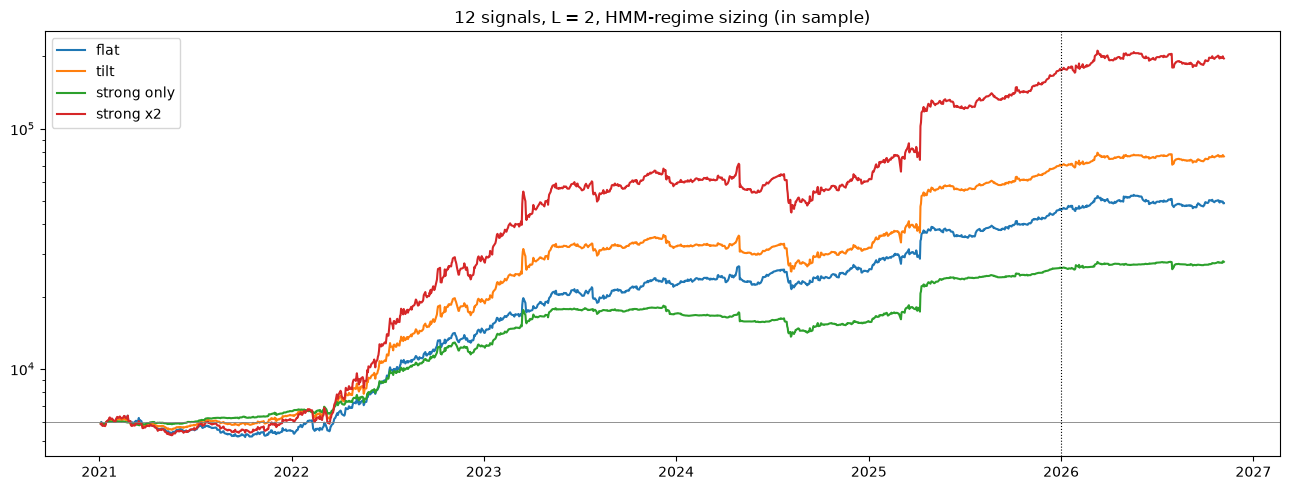

In [7]:
rowsC, curves = [], {}
for s in SCHEMES:
    Nf = NB * W[s]
    for per, sel in (("2021-2026", oos), ("2026", idx.year == 2026)):
        for L in LEVERAGES:
            acc = F.simulate_account(Nf.loc[sel], pd.Series(float(L), index=Nf.columns), E0)
            st = F.account_stats(acc, E0)
            if per == "2021-2026":
                curves[(s, L)] = acc
            rowsC.append({"scheme": s, "period": per, "L": L, "avg weight": float(W[s][sel].to_numpy().mean()), "final_equity": round(st["final_equity"]),
                          "cagr %": round(100 * st["cagr"], 1), "sharpe": round(st["sharpe"], 2), "max dd %": round(100 * st["max_drawdown"], 1),
                          "worst year %": round(100 * st["worst_year"], 1), "worst day %": round(100 * acc["ret"].min(), 1)})
Ct = pd.DataFrame(rowsC); Ct.to_csv(OUT / "13b_account.csv", index=False)
for v in ("cagr %", "sharpe", "max dd %", "worst day %"):
    print(v); display(Ct.pivot_table(index="scheme", columns=["period", "L"], values=v).reindex(list(SCHEMES)))
yrs = {}
for s in SCHEMES:
    e = curves[(s, 2)]["equity"].resample("YE").last()
    r = e.pct_change(); r.iloc[0] = e.iloc[0] / E0 - 1; r.index = r.index.year
    yrs[s] = 100 * r
print("yearly return %, L = 2:"); display(pd.DataFrame(yrs).round(1))
fig, ax = plt.subplots(figsize=(13, 5))
for s in SCHEMES:
    ax.plot(curves[(s, 2)]["equity"], label=s)
ax.set_yscale("log"); ax.axhline(E0, color="grey", lw=0.6); ax.axvline(pd.Timestamp("2026-01-01"), color="black", ls=":", lw=0.8)
ax.legend(); ax.set_title("12 signals, L = 2, HMM-regime sizing (in sample)")
plt.tight_layout(); plt.savefig(OUT / "13b_equity_2x.png", dpi=110); plt.show()

In [8]:
summary = {"study": "FXS13b", "in_sample": True, "synthetic": SYNTHETIC, "fix_group": FIX, "schemes": SCHEMES,
           "account": Ct.to_dict(orient="records"), "signals": S1.round(4).to_dict(orient="records")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\13b\summary.json
